# **<center>2X2 Rubik Cube Beam Search<center>**

### **<center>Group Member: Emre Gucer, Zhenxiang (Steven) Guan<center>**

# **<center>Introduction<center>**
  In the final project, we are discussing the application of beam search on solving 2x2 rubik cube. We will compare different heuristicfunctions' effect on the efficiency of solving the 2X2 Rubik Cube. We created the project from scratch and refer the process in homework 3. Zhenxiang(Steven) is responsible for creating the setting up and testing such as make movement, get children, and helped with creating the heuristic functions. Emre is responsible for creating beam search, testing for the functions, and shaping different heuristic functions, such as Manhattan distance, TileOutofPlace, etc.

https://www.baeldung.com/cs/beam-search   logic of beamsearch    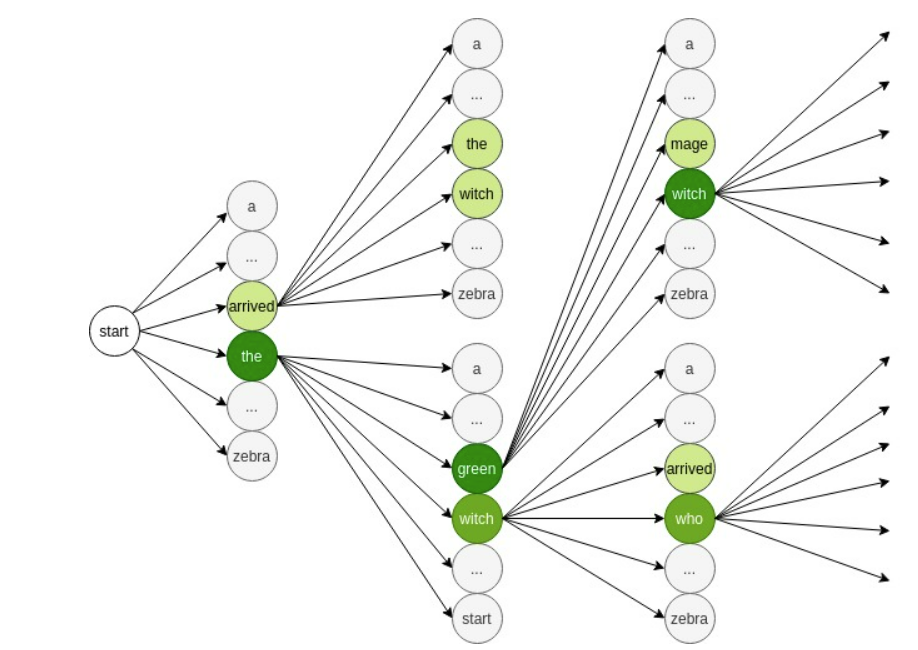

In [ ]:
WHITE = 'W'
RED ='R'
YELLOW = 'Y'
ORANGE = 'O'
BLUE = 'B'
GREEN = 'G'


#0 is top
#1 is front
#2 is left
#3 is right
#4 is behind
#5 is down
cube = [[YELLOW, YELLOW, YELLOW, YELLOW], [RED, RED, RED, RED],[BLUE, BLUE, BLUE, BLUE], [GREEN, GREEN, GREEN, GREEN], [ORANGE, ORANGE, ORANGE, ORANGE], [WHITE, WHITE, WHITE, WHITE]]



In [ ]:
print(cube)

[['Y', 'Y', 'Y', 'Y'], ['R', 'R', 'R', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'O', 'O', 'O'], ['W', 'W', 'W', 'W']]


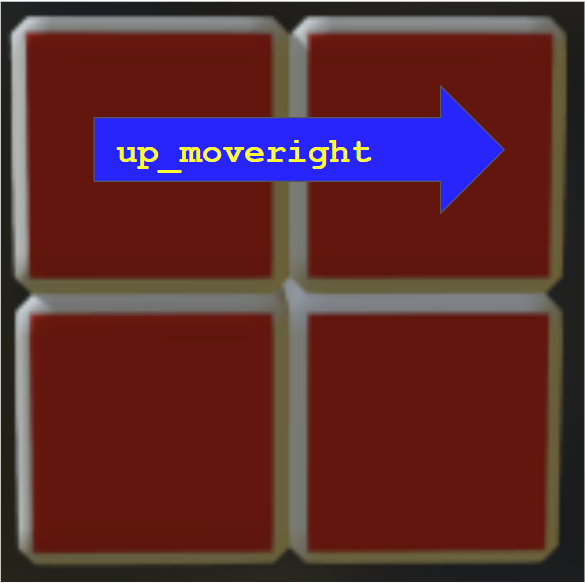

In [ ]:
import copy

def up_moveright(cube):
  copy_cube = copy.deepcopy(cube)
  copy_cube[1][0] = cube[2][0]
  copy_cube[1][1] = cube[2][1]

  copy_cube[3][0] = cube[1][0]
  copy_cube[3][1] = cube[1][1]

  copy_cube[4][0] = cube[3][0]
  copy_cube[4][1] = cube[3][1]

  copy_cube[2][0] = cube[4][0]
  copy_cube[2][1] = cube[4][1]

  return copy_cube

up_moveright(cube)


[['Y', 'Y', 'Y', 'Y'],
 ['B', 'B', 'R', 'R'],
 ['O', 'O', 'B', 'B'],
 ['R', 'R', 'G', 'G'],
 ['G', 'G', 'O', 'O'],
 ['W', 'W', 'W', 'W']]

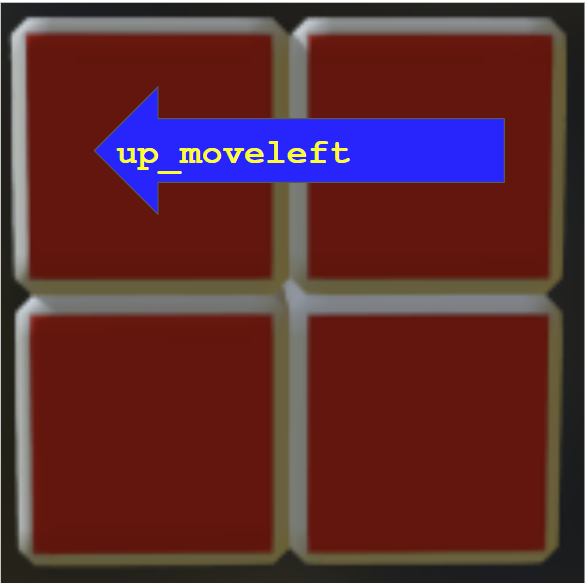

In [ ]:
def up_moveleft(cube):
  copy_cube = copy.deepcopy(cube)
  copy_cube[2][0] = cube[1][0]
  copy_cube[2][1] = cube[1][1]

  copy_cube[1][0] = cube[3][0]
  copy_cube[1][1] = cube[3][1]

  copy_cube[3][0] = cube[4][0]
  copy_cube[3][1] = cube[4][1]

  copy_cube[4][0] = cube[2][0]
  copy_cube[4][1] = cube[2][1]

  return copy_cube

up_moveleft(cube)

[['Y', 'Y', 'Y', 'Y'],
 ['G', 'G', 'R', 'R'],
 ['R', 'R', 'B', 'B'],
 ['O', 'O', 'G', 'G'],
 ['B', 'B', 'O', 'O'],
 ['W', 'W', 'W', 'W']]

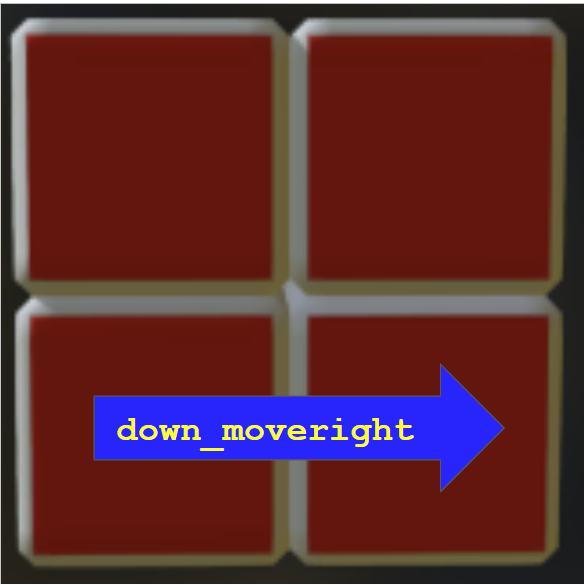

In [ ]:
def down_moveright(cube):
  copy_cube = copy.deepcopy(cube)
  copy_cube[1][2] = cube[2][2]
  copy_cube[1][3] = cube[2][3]

  copy_cube[3][2] = cube[1][2]
  copy_cube[3][3] = cube[1][3]

  copy_cube[4][2] = cube[3][2]
  copy_cube[4][3] = cube[3][3]

  copy_cube[2][2] = cube[4][2]
  copy_cube[2][3] = cube[4][3]

  return copy_cube

down_moveright(cube)


[['Y', 'Y', 'Y', 'Y'],
 ['R', 'R', 'B', 'B'],
 ['B', 'B', 'O', 'O'],
 ['G', 'G', 'R', 'R'],
 ['O', 'O', 'G', 'G'],
 ['W', 'W', 'W', 'W']]

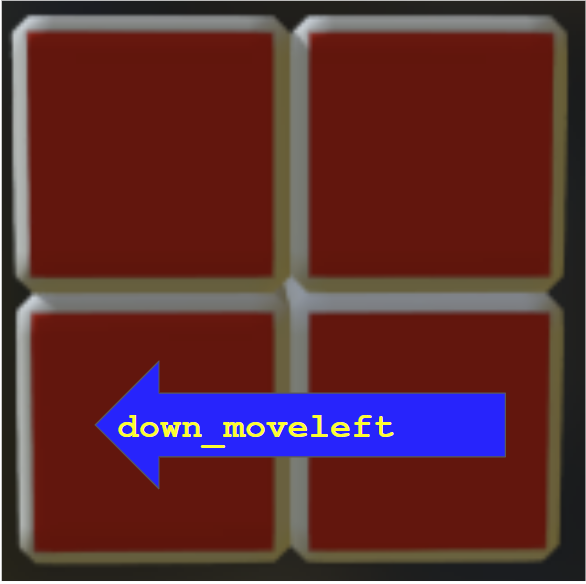

In [ ]:
def down_moveleft(cube):
  copy_cube = copy.deepcopy(cube)
  copy_cube[2][2] = cube[1][2]
  copy_cube[2][3] = cube[1][3]

  copy_cube[1][2] = cube[3][2]
  copy_cube[1][3] = cube[3][3]

  copy_cube[3][2] = cube[4][2]
  copy_cube[3][3] = cube[4][3]

  copy_cube[4][2] = cube[2][2]
  copy_cube[4][3] = cube[2][3]

  return copy_cube

down_moveleft(cube)

[['Y', 'Y', 'Y', 'Y'],
 ['R', 'R', 'G', 'G'],
 ['B', 'B', 'R', 'R'],
 ['G', 'G', 'O', 'O'],
 ['O', 'O', 'B', 'B'],
 ['W', 'W', 'W', 'W']]

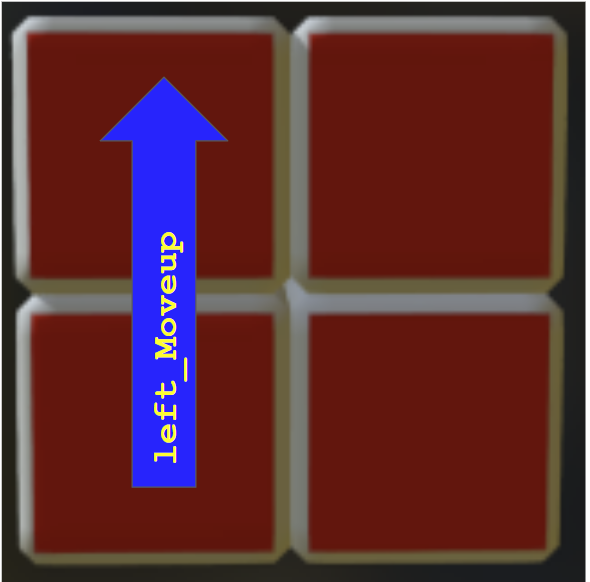

In [ ]:
def left_Moveup(cube):
  copy_cube = copy.deepcopy(cube)
  copy_cube[0][0] = cube[1][0]
  copy_cube[0][2] = cube[1][2]

  copy_cube[1][0] = cube[5][0]
  copy_cube[1][2] = cube[5][2]

  copy_cube[5][0] = cube[4][3]
  copy_cube[5][2] = cube[4][1]

  copy_cube[4][1] = cube[0][2]
  copy_cube[4][3] = cube[0][0]

  return copy_cube

left_Moveup(cube)

[['R', 'Y', 'R', 'Y'],
 ['W', 'R', 'W', 'R'],
 ['B', 'B', 'B', 'B'],
 ['G', 'G', 'G', 'G'],
 ['O', 'Y', 'O', 'Y'],
 ['O', 'W', 'O', 'W']]

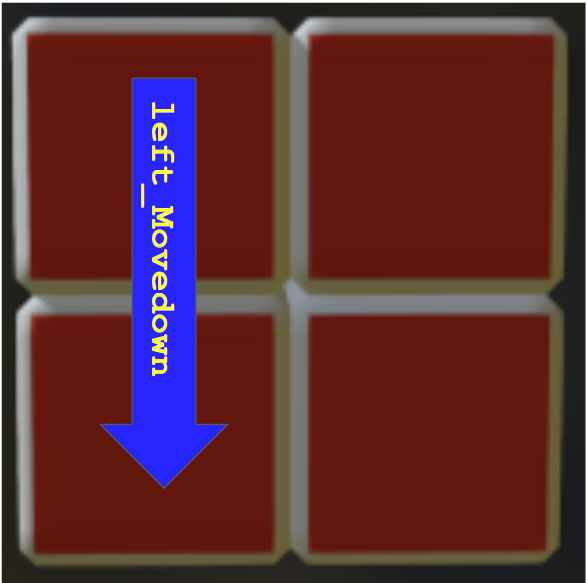

In [ ]:
def left_Movedown(cube):
  copy_cube = copy.deepcopy(cube)
  copy_cube[0][0] = cube[4][3]
  copy_cube[0][2] = cube[4][1]

  copy_cube[1][0] = cube[0][0]
  copy_cube[1][2] = cube[0][2]

  copy_cube[5][0] = cube[1][0]
  copy_cube[5][2] = cube[1][2]

  copy_cube[4][3] = cube[5][0]
  copy_cube[4][1] = cube[5][2]

  return copy_cube

left_Movedown(cube)

[['O', 'Y', 'O', 'Y'],
 ['Y', 'R', 'Y', 'R'],
 ['B', 'B', 'B', 'B'],
 ['G', 'G', 'G', 'G'],
 ['O', 'W', 'O', 'W'],
 ['R', 'W', 'R', 'W']]

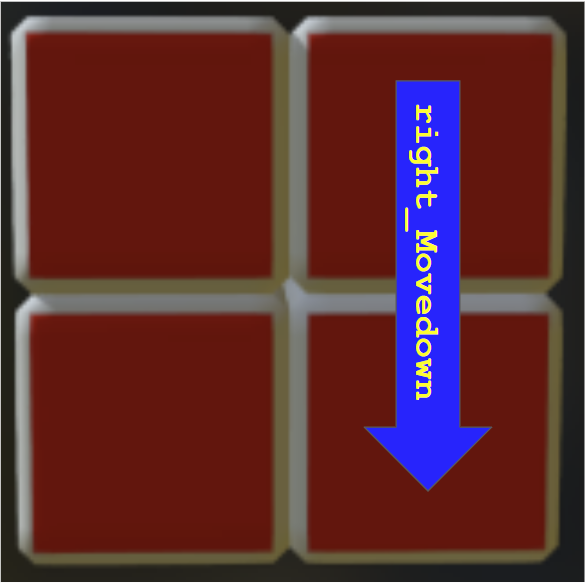

In [ ]:
def right_Movedown(cube):
  copy_cube = copy.deepcopy(cube)
  copy_cube[0][1] = cube[4][2]
  copy_cube[0][3] = cube[4][0]

  copy_cube[1][1] = cube[0][1]
  copy_cube[1][3] = cube[0][3]

  copy_cube[5][1] = cube[1][1]
  copy_cube[5][3] = cube[1][3]

  copy_cube[4][2] = cube[5][1]
  copy_cube[4][0] = cube[5][3]

  return copy_cube

right_Movedown(cube)

[['Y', 'O', 'Y', 'O'],
 ['R', 'Y', 'R', 'Y'],
 ['B', 'B', 'B', 'B'],
 ['G', 'G', 'G', 'G'],
 ['W', 'O', 'W', 'O'],
 ['W', 'R', 'W', 'R']]

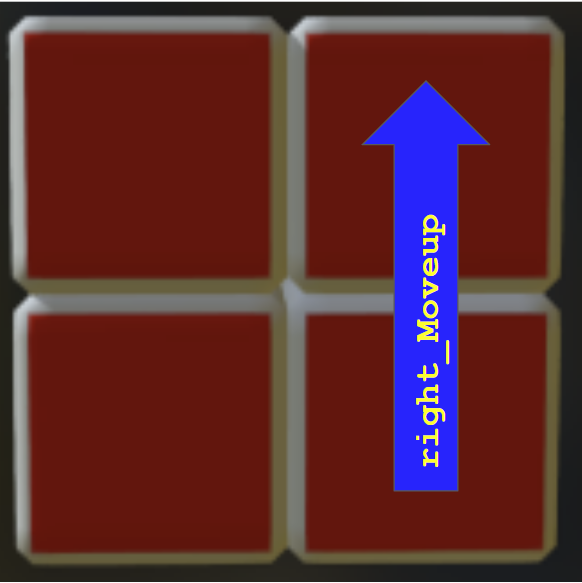

In [ ]:
def right_Moveup(cube):
  copy_cube = copy.deepcopy(cube)
  copy_cube[0][1] = cube[1][1]
  copy_cube[0][3] = cube[1][3]

  copy_cube[1][1] = cube[5][1]
  copy_cube[1][3] = cube[5][3]

  copy_cube[5][1] = cube[4][2]
  copy_cube[5][3] = cube[4][0]

  copy_cube[4][0] = cube[0][3]
  copy_cube[4][2] = cube[0][1]

  return copy_cube

right_Moveup(cube)

[['Y', 'R', 'Y', 'R'],
 ['R', 'W', 'R', 'W'],
 ['B', 'B', 'B', 'B'],
 ['G', 'G', 'G', 'G'],
 ['Y', 'O', 'Y', 'O'],
 ['W', 'O', 'W', 'O']]

In [ ]:
finishedCube1 = [[YELLOW, YELLOW, YELLOW, YELLOW], [RED, RED, RED, RED],[BLUE, BLUE, BLUE, BLUE], [GREEN, GREEN, GREEN, GREEN], [ORANGE, ORANGE, ORANGE, ORANGE], [WHITE, WHITE, WHITE, WHITE]]
finishedCube2 = [[YELLOW, YELLOW, YELLOW, YELLOW], [GREEN, GREEN, GREEN, GREEN],[RED, RED, RED, RED],[ORANGE, ORANGE, ORANGE, ORANGE], [BLUE, BLUE, BLUE, BLUE],  [WHITE, WHITE, WHITE, WHITE]]
finishedCube3 = [[YELLOW, YELLOW, YELLOW, YELLOW], [ORANGE, ORANGE, ORANGE, ORANGE], [GREEN, GREEN, GREEN, GREEN], [BLUE, BLUE, BLUE, BLUE], [RED, RED, RED, RED],   [WHITE, WHITE, WHITE, WHITE]]
finishedCube4 = [[YELLOW, YELLOW, YELLOW, YELLOW], [BLUE, BLUE, BLUE, BLUE], [ORANGE, ORANGE, ORANGE, ORANGE], [RED, RED, RED, RED], [GREEN, GREEN, GREEN, GREEN],   [WHITE, WHITE, WHITE, WHITE]]
finishedCube5 = [[RED, RED, RED, RED], [YELLOW, YELLOW, YELLOW, YELLOW], [GREEN, GREEN, GREEN, GREEN],[BLUE, BLUE, BLUE, BLUE],  [WHITE, WHITE, WHITE, WHITE],  [ORANGE, ORANGE, ORANGE, ORANGE]]
finishedCube6 = [[RED, RED, RED, RED], [BLUE, BLUE, BLUE, BLUE], [YELLOW, YELLOW, YELLOW, YELLOW],[WHITE, WHITE, WHITE, WHITE],  [GREEN, GREEN, GREEN, GREEN],  [ORANGE, ORANGE, ORANGE, ORANGE]]
finishedCube7 = [[RED, RED, RED, RED], [WHITE, WHITE, WHITE, WHITE], [BLUE, BLUE, BLUE, BLUE],[GREEN, GREEN, GREEN, GREEN], [YELLOW, YELLOW, YELLOW, YELLOW],[ORANGE, ORANGE, ORANGE, ORANGE]]
finishedCube8 = [[RED, RED, RED, RED], [GREEN, GREEN, GREEN, GREEN], [WHITE, WHITE, WHITE, WHITE], [YELLOW, YELLOW, YELLOW, YELLOW], [BLUE, BLUE, BLUE, BLUE], [ORANGE, ORANGE, ORANGE, ORANGE]]
finishedCube9 = [[BLUE, BLUE, BLUE, BLUE], [YELLOW, YELLOW, YELLOW, YELLOW], [RED, RED, RED, RED], [ORANGE, ORANGE, ORANGE, ORANGE], [WHITE, WHITE, WHITE, WHITE],  [GREEN, GREEN, GREEN, GREEN]]
finishedCube10 = [[BLUE, BLUE, BLUE, BLUE], [RED, RED, RED, RED], [WHITE, WHITE, WHITE, WHITE],[YELLOW, YELLOW, YELLOW, YELLOW],  [ORANGE, ORANGE, ORANGE, ORANGE], [GREEN, GREEN, GREEN, GREEN]]
finishedCube11 = [[BLUE, BLUE, BLUE, BLUE],  [ORANGE, ORANGE, ORANGE, ORANGE], [YELLOW, YELLOW, YELLOW, YELLOW], [WHITE, WHITE, WHITE, WHITE],  [RED, RED, RED, RED],  [GREEN, GREEN, GREEN, GREEN]]
finishedCube12 = [[BLUE, BLUE, BLUE, BLUE], [WHITE, WHITE, WHITE, WHITE],  [ORANGE, ORANGE, ORANGE, ORANGE], [RED, RED, RED, RED], [YELLOW, YELLOW, YELLOW, YELLOW],  [GREEN, GREEN, GREEN, GREEN]]
finishedCube13 = [[GREEN, GREEN, GREEN, GREEN], [YELLOW, YELLOW, YELLOW, YELLOW],  [ORANGE, ORANGE, ORANGE, ORANGE], [RED, RED, RED, RED], [WHITE, WHITE, WHITE, WHITE],  [BLUE, BLUE, BLUE, BLUE]]
finishedCube14 = [[GREEN, GREEN, GREEN, GREEN], [RED, RED, RED, RED],[YELLOW, YELLOW, YELLOW, YELLOW], [WHITE, WHITE, WHITE, WHITE], [ORANGE, ORANGE, ORANGE, ORANGE], [BLUE, BLUE, BLUE, BLUE]]
finishedCube15 = [[GREEN, GREEN, GREEN, GREEN],  [ORANGE, ORANGE, ORANGE, ORANGE], [WHITE, WHITE, WHITE, WHITE], [YELLOW, YELLOW, YELLOW, YELLOW], [RED, RED, RED, RED],  [BLUE, BLUE, BLUE, BLUE]]
finishedCube16 = [[GREEN, GREEN, GREEN, GREEN], [WHITE, WHITE, WHITE, WHITE],  [RED, RED, RED, RED], [ORANGE, ORANGE, ORANGE, ORANGE],[YELLOW, YELLOW, YELLOW, YELLOW],  [BLUE, BLUE, BLUE, BLUE]]
finishedCube17 = [[ORANGE, ORANGE, ORANGE, ORANGE], [YELLOW, YELLOW, YELLOW, YELLOW], [BLUE, BLUE, BLUE, BLUE], [GREEN, GREEN, GREEN, GREEN],  [WHITE, WHITE, WHITE, WHITE],  [RED, RED, RED, RED]]
finishedCube18 = [[ORANGE, ORANGE, ORANGE, ORANGE], [BLUE, BLUE, BLUE, BLUE], [WHITE, WHITE, WHITE, WHITE], [YELLOW, YELLOW, YELLOW, YELLOW],  [GREEN, GREEN, GREEN, GREEN],  [RED, RED, RED, RED]]
finishedCube19 = [[ORANGE, ORANGE, ORANGE, ORANGE], [WHITE, WHITE, WHITE, WHITE], [GREEN, GREEN, GREEN, GREEN],[BLUE, BLUE, BLUE, BLUE], [YELLOW, YELLOW, YELLOW, YELLOW],[RED, RED, RED, RED]]
finishedCube20 = [[ORANGE, ORANGE, ORANGE, ORANGE], [GREEN, GREEN, GREEN, GREEN], [YELLOW, YELLOW, YELLOW, YELLOW],[WHITE, WHITE, WHITE, WHITE],  [BLUE, BLUE, BLUE, BLUE], [RED, RED, RED, RED]]
finishedCube21 = [[WHITE, WHITE, WHITE, WHITE], [RED, RED, RED, RED], [GREEN, GREEN, GREEN, GREEN], [BLUE, BLUE, BLUE, BLUE],  [ORANGE, ORANGE, ORANGE, ORANGE], [YELLOW, YELLOW, YELLOW, YELLOW]]
finishedCube22 = [[WHITE, WHITE, WHITE, WHITE], [GREEN, GREEN, GREEN, GREEN],[ORANGE, ORANGE, ORANGE, ORANGE], [RED, RED, RED, RED], [BLUE, BLUE, BLUE, BLUE],  [YELLOW, YELLOW, YELLOW, YELLOW]]
finishedCube23 = [[WHITE, WHITE, WHITE, WHITE], [ORANGE, ORANGE, ORANGE, ORANGE], [BLUE, BLUE, BLUE, BLUE], [GREEN, GREEN, GREEN, GREEN], [RED, RED, RED, RED],   [YELLOW, YELLOW, YELLOW, YELLOW]]
finishedCube24 = [[WHITE, WHITE, WHITE, WHITE], [BLUE, BLUE, BLUE, BLUE], [RED, RED, RED, RED], [ORANGE, ORANGE, ORANGE, ORANGE], [GREEN, GREEN, GREEN, GREEN],  [YELLOW, YELLOW, YELLOW, YELLOW]]

In [ ]:
complete_cube_list = [finishedCube1,finishedCube2,finishedCube3,finishedCube4,finishedCube5,
                      finishedCube6,finishedCube7,finishedCube8,finishedCube9,finishedCube10,
                      finishedCube11,finishedCube12,finishedCube13,finishedCube14,finishedCube15,
                      finishedCube16,finishedCube17,finishedCube18,finishedCube19,finishedCube20,
                      finishedCube21,finishedCube22,finishedCube23,finishedCube24]

In [ ]:
#basically random moves
def noHeuristic(cubeModify):
  return 0

In [ ]:
import sys

def tilesOutOfPlace(cubeModify):
  tilesOutOfPlace = sys.maxsize
  for finishedCubeIndex in range(len(complete_cube_list)): #compare with each cube
    outOfPlace = 0
    for faceIndex in range(len(cubeModify)): #get the face
      for tile in range (len(cubeModify[faceIndex])): #for each tile
        if (not cubeModify[faceIndex][tile] == complete_cube_list[finishedCubeIndex][faceIndex][tile]): #if they are different
          outOfPlace += 1 #add 1
    if(outOfPlace < tilesOutOfPlace):
      tilesOutOfPlace = outOfPlace
  return tilesOutOfPlace

tilesOutOfPlace(cube)

0

In [ ]:
cube_fake_one_diff = [[RED, YELLOW, YELLOW, YELLOW],
                      [RED, RED, RED, RED],
                      [BLUE, BLUE, BLUE, BLUE],
                      [GREEN, GREEN, GREEN, GREEN],
                      [ORANGE, ORANGE, ORANGE, ORANGE],
                      [WHITE, WHITE, WHITE, WHITE]]
tilesOutOfPlace(cube_fake_one_diff)

1

In [ ]:
cube_fake = [['O', 'Y', 'O', 'Y'],
 ['Y', 'R', 'Y', 'R'],
 ['B', 'B', 'B', 'B'],
 ['G', 'G', 'G', 'G'],
 ['O', 'W', 'O', 'W'],
 ['R', 'W', 'R', 'W']]
tilesOutOfPlace(cube_fake)

8

In [ ]:
cube_fake_diff2 = [[RED, WHITE, GREEN, WHITE],
             [WHITE, BLUE, WHITE, ORANGE],
             [BLUE, RED, BLUE, RED],
             [ORANGE, ORANGE, GREEN, GREEN],
             [GREEN, YELLOW, RED, YELLOW],
             [BLUE, YELLOW, ORANGE, YELLOW]]
tilesOutOfPlace(cube_fake_diff2)

14

In [ ]:
def manhattanDistance(cubeModify):
  ManhattanDistance = sys.maxsize
  for finishedCubeIndex in range(len(complete_cube_list)): #compare with each cube
    distance = 0
    for faceIndex in range(len(cubeModify)): #get the face
      for tile in range (len(cubeModify[faceIndex])): #for each tile
        if (not cubeModify[faceIndex][tile] == complete_cube_list[finishedCubeIndex][faceIndex][tile]): #if they are different
          color = cubeModify[faceIndex][tile]
          face = -1 #find which face it needs to be
          for eachFace in range(len(complete_cube_list[finishedCubeIndex])):
            if(complete_cube_list[finishedCubeIndex][eachFace][0] == color):
              face = eachFace
          if ((face == 0 and faceIndex == 5) or (face == 1 and faceIndex == 4) or (face == 2 and faceIndex == 3)
          or (face == 3 and faceIndex == 2) or (face == 4 and faceIndex == 1) or (face == 5 and faceIndex == 0)):
            distance += 2
          else:
            distance += 1

    if(distance < ManhattanDistance):
      ManhattanDistance = distance
  return ManhattanDistance

In [ ]:
manhattanDistance(cube)

0

In [ ]:
manhattanDistance(cube_fake_one_diff)

1

In [ ]:
cube_fake_new = up_moveright(cube)

manhattanDistance(cube_fake_new)

8

In [ ]:
cube_fake_new2 = right_Movedown(cube_fake_new)
manhattanDistance(cube_fake_new2)

14

In [ ]:
def checkCube(scrambledCube):
  if(scrambledCube in complete_cube_list):
    return True
  return False

In [ ]:
checkCube(cube)

True

In [ ]:
checkCube(cube_fake)

False

In [ ]:
checkCube(cube_fake_diff2)

False

In [ ]:
exampleFinished = [[RED, RED, RED, RED], [GREEN, GREEN, GREEN, GREEN], [WHITE, WHITE, WHITE, WHITE], [YELLOW, YELLOW, YELLOW, YELLOW], [BLUE, BLUE, BLUE, BLUE], [ORANGE, ORANGE, ORANGE, ORANGE]]
checkCube(exampleFinished)

True

In [ ]:
checkCube(finishedCube17)

True

In [ ]:
def getChildren(inputCube):
  children = []
  if (not inputCube[1] ==""):
    children.append((up_moveright(inputCube[0]), inputCube[1] + ",up_moveright"))
    children.append((up_moveleft(inputCube[0]), inputCube[1] + ",up_moveleft"))
    children.append((down_moveright(inputCube[0]), inputCube[1] + ",down_moveright"))
    children.append((down_moveleft(inputCube[0]), inputCube[1] + ",down_moveleft"))
    children.append((left_Moveup(inputCube[0]), inputCube[1] + ",left_Moveup"))
    children.append((left_Movedown(inputCube[0]), inputCube[1] + ",left_Movedown"))
    children.append((right_Movedown(inputCube[0]), inputCube[1] + ",right_Movedown"))
    children.append((right_Moveup(inputCube[0]), inputCube[1] + ",right_Moveup"))
  else:
    children.append((up_moveright(inputCube[0]), inputCube[1] + "up_moveright"))
    children.append((up_moveleft(inputCube[0]), inputCube[1] + "up_moveleft"))
    children.append((down_moveright(inputCube[0]), inputCube[1] + "down_moveright"))
    children.append((down_moveleft(inputCube[0]), inputCube[1] + "down_moveleft"))
    children.append((left_Moveup(inputCube[0]), inputCube[1] + "left_Moveup"))
    children.append((left_Movedown(inputCube[0]), inputCube[1] + "left_Movedown"))
    children.append((right_Movedown(inputCube[0]), inputCube[1] + "right_Movedown"))
    children.append((right_Moveup(inputCube[0]), inputCube[1] + "right_Moveup"))
  return children

getChildren((cube, ""))

[([['Y', 'Y', 'Y', 'Y'],
   ['B', 'B', 'R', 'R'],
   ['O', 'O', 'B', 'B'],
   ['R', 'R', 'G', 'G'],
   ['G', 'G', 'O', 'O'],
   ['W', 'W', 'W', 'W']],
  'up_moveright'),
 ([['Y', 'Y', 'Y', 'Y'],
   ['G', 'G', 'R', 'R'],
   ['R', 'R', 'B', 'B'],
   ['O', 'O', 'G', 'G'],
   ['B', 'B', 'O', 'O'],
   ['W', 'W', 'W', 'W']],
  'up_moveleft'),
 ([['Y', 'Y', 'Y', 'Y'],
   ['R', 'R', 'B', 'B'],
   ['B', 'B', 'O', 'O'],
   ['G', 'G', 'R', 'R'],
   ['O', 'O', 'G', 'G'],
   ['W', 'W', 'W', 'W']],
  'down_moveright'),
 ([['Y', 'Y', 'Y', 'Y'],
   ['R', 'R', 'G', 'G'],
   ['B', 'B', 'R', 'R'],
   ['G', 'G', 'O', 'O'],
   ['O', 'O', 'B', 'B'],
   ['W', 'W', 'W', 'W']],
  'down_moveleft'),
 ([['R', 'Y', 'R', 'Y'],
   ['W', 'R', 'W', 'R'],
   ['B', 'B', 'B', 'B'],
   ['G', 'G', 'G', 'G'],
   ['O', 'Y', 'O', 'Y'],
   ['O', 'W', 'O', 'W']],
  'left_Moveup'),
 ([['O', 'Y', 'O', 'Y'],
   ['Y', 'R', 'Y', 'R'],
   ['B', 'B', 'B', 'B'],
   ['G', 'G', 'G', 'G'],
   ['O', 'W', 'O', 'W'],
   ['R', 'W', 'R', 'W']]

In [ ]:
def searchOnce(scrambledCubes, heuristicFunction, beamWidth, previouslyAppeared):
  cubes = []
  for eachCube in scrambledCubes:
    resultedCubes = getChildren(eachCube)
    for eachNewCube in resultedCubes:
      cubes.append(eachNewCube)
  childList = []
  for child in cubes:
    child_with_result = (child[0], child[1], heuristicFunction(child[0]))
    if(not (child[0] in previouslyAppeared)): #to prevent loops
      childList.append(child_with_result)
  childList.sort(key=lambda a: a[2])
  child_tuple_list = childList[0:beamWidth]
  return child_tuple_list

In [ ]:
givenCubeAndMoves = (cube_fake_new, "up_moveright")
searchOnce([givenCubeAndMoves], manhattanDistance, 2, [])

[([['Y', 'Y', 'Y', 'Y'],
   ['R', 'R', 'R', 'R'],
   ['B', 'B', 'B', 'B'],
   ['G', 'G', 'G', 'G'],
   ['O', 'O', 'O', 'O'],
   ['W', 'W', 'W', 'W']],
  'up_moveright,up_moveleft',
  0),
 ([['Y', 'Y', 'Y', 'Y'],
   ['B', 'B', 'B', 'B'],
   ['O', 'O', 'O', 'O'],
   ['R', 'R', 'R', 'R'],
   ['G', 'G', 'G', 'G'],
   ['W', 'W', 'W', 'W']],
  'up_moveright,down_moveright',
  0)]

In [ ]:
givenCubeAndMoves1 = (cube_fake_new, "up_moveright")
givenCubeAndMoves2 = (right_Movedown(cube_fake_new), "up_moveright,right_Movedown")
searchOnce([givenCubeAndMoves1, givenCubeAndMoves2], manhattanDistance, 5, [])

[([['Y', 'Y', 'Y', 'Y'],
   ['R', 'R', 'R', 'R'],
   ['B', 'B', 'B', 'B'],
   ['G', 'G', 'G', 'G'],
   ['O', 'O', 'O', 'O'],
   ['W', 'W', 'W', 'W']],
  'up_moveright,up_moveleft',
  0),
 ([['Y', 'Y', 'Y', 'Y'],
   ['B', 'B', 'B', 'B'],
   ['O', 'O', 'O', 'O'],
   ['R', 'R', 'R', 'R'],
   ['G', 'G', 'G', 'G'],
   ['W', 'W', 'W', 'W']],
  'up_moveright,down_moveright',
  0),
 ([['Y', 'O', 'Y', 'G'],
   ['R', 'R', 'R', 'Y'],
   ['B', 'Y', 'B', 'B'],
   ['W', 'G', 'G', 'G'],
   ['O', 'O', 'W', 'O'],
   ['W', 'B', 'W', 'R']],
  'up_moveright,right_Movedown,up_moveleft',
  8),
 ([['Y', 'O', 'Y', 'G'],
   ['B', 'Y', 'B', 'B'],
   ['O', 'O', 'W', 'O'],
   ['R', 'R', 'R', 'Y'],
   ['W', 'G', 'G', 'G'],
   ['W', 'B', 'W', 'R']],
  'up_moveright,right_Movedown,down_moveright',
  8),
 ([['O', 'O', 'G', 'G'],
   ['Y', 'Y', 'Y', 'Y'],
   ['O', 'O', 'B', 'B'],
   ['R', 'R', 'G', 'G'],
   ['W', 'W', 'W', 'W'],
   ['B', 'B', 'R', 'R']],
  'up_moveright,right_Movedown,left_Movedown',
  8)]

In [ ]:
def beamSearch(scrambledCube, heuristicFunction, beamWidth, maxIterations):
  previouslyAppeared = []
  if not (checkCube(scrambledCube)):
    requiredActionCount = 0
    scrambledCubes = []
    scrambledCubes.append((scrambledCube, ""))
    i = 0
    while(i < maxIterations):
      i +=1
      scrambledCubes = searchOnce(scrambledCubes, heuristicFunction, beamWidth, previouslyAppeared)
      solutions = []
      solved = False
      for eachCube in scrambledCubes:
        if((checkCube(eachCube[0]))):
          solved = True
          solutions.append(eachCube)
      if(solved):
        return solutions
  else:
    return (scrambledCube, '', 0)

In [ ]:
beamSearch(cube, manhattanDistance, 2, 80)

([['Y', 'Y', 'Y', 'Y'],
  ['R', 'R', 'R', 'R'],
  ['B', 'B', 'B', 'B'],
  ['G', 'G', 'G', 'G'],
  ['O', 'O', 'O', 'O'],
  ['W', 'W', 'W', 'W']],
 '',
 0)

In [ ]:
upTurnedOnce = up_moveright(cube)
beamSearch(upTurnedOnce, manhattanDistance, 2, 80)

[([['Y', 'Y', 'Y', 'Y'],
   ['R', 'R', 'R', 'R'],
   ['B', 'B', 'B', 'B'],
   ['G', 'G', 'G', 'G'],
   ['O', 'O', 'O', 'O'],
   ['W', 'W', 'W', 'W']],
  'up_moveleft',
  0),
 ([['Y', 'Y', 'Y', 'Y'],
   ['B', 'B', 'B', 'B'],
   ['O', 'O', 'O', 'O'],
   ['R', 'R', 'R', 'R'],
   ['G', 'G', 'G', 'G'],
   ['W', 'W', 'W', 'W']],
  'down_moveright',
  0)]

In [ ]:
upTurnedThen = up_moveright(upTurnedOnce)

beamSearch(upTurnedThen, manhattanDistance, 2, 80)

[([['Y', 'Y', 'Y', 'Y'],
   ['R', 'R', 'R', 'R'],
   ['B', 'B', 'B', 'B'],
   ['G', 'G', 'G', 'G'],
   ['O', 'O', 'O', 'O'],
   ['W', 'W', 'W', 'W']],
  'up_moveright,up_moveright',
  0),
 ([['Y', 'Y', 'Y', 'Y'],
   ['G', 'G', 'G', 'G'],
   ['R', 'R', 'R', 'R'],
   ['O', 'O', 'O', 'O'],
   ['B', 'B', 'B', 'B'],
   ['W', 'W', 'W', 'W']],
  'up_moveright,down_moveleft',
  0)]

In [ ]:
rightDownSingle = right_Movedown(upTurnedOnce)
beamSearch(rightDownSingle, manhattanDistance, 4, 80) #having as many child is better (larger width increases probability of finding a solution)

[([['Y', 'Y', 'Y', 'Y'],
   ['R', 'R', 'R', 'R'],
   ['B', 'B', 'B', 'B'],
   ['G', 'G', 'G', 'G'],
   ['O', 'O', 'O', 'O'],
   ['W', 'W', 'W', 'W']],
  'right_Moveup,up_moveleft',
  0),
 ([['Y', 'Y', 'Y', 'Y'],
   ['B', 'B', 'B', 'B'],
   ['O', 'O', 'O', 'O'],
   ['R', 'R', 'R', 'R'],
   ['G', 'G', 'G', 'G'],
   ['W', 'W', 'W', 'W']],
  'right_Moveup,down_moveright',
  0)]

In [ ]:
def beamSearchMain(scrambledCube, heuristicFunction, beamWidth, maxIterations):
  solutions = beamSearch(scrambledCube, heuristicFunction, beamWidth, maxIterations)
  if (solutions == None):
    print("Failed to solve the cube!")
  elif(not solutions == []):
    print("Managed to solve the cube!")
    print("There are: " + str(len(solutions)) + " solutions found as simplest paths.")
    print()
    print("Given cube:")
    print(scrambledCube)
    print()
    tempCube = scrambledCube
    for i in range(len(solutions)):
      scrambledCube = tempCube
      iteration = i + 1
      print("Solution number " + str(iteration) + ":")
      movesAsString = solutions[i][1]
      moves = movesAsString.split(",")
      for move in moves:
        print(move)
        if (move == "up_moveright"):
          scrambledCube = up_moveright(scrambledCube)
        if (move == "up_moveleft"):
          scrambledCube = up_moveleft(scrambledCube)
        if (move == "down_moveright"):
          scrambledCube = down_moveright(scrambledCube)
        if (move == "down_moveleft"):
          scrambledCube = down_moveleft(scrambledCube)
        if (move == "left_Moveup"):
          scrambledCube = left_Moveup(scrambledCube)
        if (move == "left_Movedown"):
          scrambledCube = left_Movedown(scrambledCube)
        if (move == "right_Movedown"):
          scrambledCube = right_Movedown(scrambledCube)
        if (move == "right_Moveup"):
          scrambledCube = right_Moveup(scrambledCube)
        print(scrambledCube)
      print("--------------------------------------------------------------------------------------------------------------------------------------")


In [ ]:
#beamSearchMain(scrambledCube, heuristicFunction, beamWidth, maxIterations)

In [ ]:
beamSearchMain(upTurnedOnce, noHeuristic, 4, 80)

Managed to solve the cube!
There are: 2 solutions found as simplest paths.

Given cube:
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'R', 'R'], ['O', 'O', 'B', 'B'], ['R', 'R', 'G', 'G'], ['G', 'G', 'O', 'O'], ['W', 'W', 'W', 'W']]

Solution number 1:
up_moveleft
[['Y', 'Y', 'Y', 'Y'], ['R', 'R', 'R', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'O', 'O', 'O'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------
Solution number 2:
down_moveright
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'B', 'B'], ['O', 'O', 'O', 'O'], ['R', 'R', 'R', 'R'], ['G', 'G', 'G', 'G'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
beamSearchMain(upTurnedOnce, tilesOutOfPlace, 4, 80)

Managed to solve the cube!
There are: 2 solutions found as simplest paths.

Given cube:
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'R', 'R'], ['O', 'O', 'B', 'B'], ['R', 'R', 'G', 'G'], ['G', 'G', 'O', 'O'], ['W', 'W', 'W', 'W']]

Solution number 1:
up_moveleft
[['Y', 'Y', 'Y', 'Y'], ['R', 'R', 'R', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'O', 'O', 'O'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------
Solution number 2:
down_moveright
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'B', 'B'], ['O', 'O', 'O', 'O'], ['R', 'R', 'R', 'R'], ['G', 'G', 'G', 'G'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
beamSearchMain(upTurnedOnce, manhattanDistance, 4, 80)

Managed to solve the cube!
There are: 2 solutions found as simplest paths.

Given cube:
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'R', 'R'], ['O', 'O', 'B', 'B'], ['R', 'R', 'G', 'G'], ['G', 'G', 'O', 'O'], ['W', 'W', 'W', 'W']]

Solution number 1:
up_moveleft
[['Y', 'Y', 'Y', 'Y'], ['R', 'R', 'R', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'O', 'O', 'O'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------
Solution number 2:
down_moveright
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'B', 'B'], ['O', 'O', 'O', 'O'], ['R', 'R', 'R', 'R'], ['G', 'G', 'G', 'G'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
beamSearchMain(rightDownSingle, manhattanDistance, 4, 80)

Managed to solve the cube!
There are: 2 solutions found as simplest paths.

Given cube:
[['Y', 'O', 'Y', 'G'], ['B', 'Y', 'R', 'Y'], ['O', 'O', 'B', 'B'], ['R', 'R', 'G', 'G'], ['W', 'G', 'W', 'O'], ['W', 'B', 'W', 'R']]

Solution number 1:
right_Moveup
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'R', 'R'], ['O', 'O', 'B', 'B'], ['R', 'R', 'G', 'G'], ['G', 'G', 'O', 'O'], ['W', 'W', 'W', 'W']]
up_moveleft
[['Y', 'Y', 'Y', 'Y'], ['R', 'R', 'R', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'O', 'O', 'O'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------
Solution number 2:
right_Moveup
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'R', 'R'], ['O', 'O', 'B', 'B'], ['R', 'R', 'G', 'G'], ['G', 'G', 'O', 'O'], ['W', 'W', 'W', 'W']]
down_moveright
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'B', 'B'], ['O', 'O', 'O', 'O'], ['R', 'R', 'R', 'R'], ['G', 'G', 'G', 'G'], ['W', 'W', 'W', 'W']]
--------------------

In [ ]:
beamSearchMain(rightDownSingle, tilesOutOfPlace, 4, 80)

Managed to solve the cube!
There are: 2 solutions found as simplest paths.

Given cube:
[['Y', 'O', 'Y', 'G'], ['B', 'Y', 'R', 'Y'], ['O', 'O', 'B', 'B'], ['R', 'R', 'G', 'G'], ['W', 'G', 'W', 'O'], ['W', 'B', 'W', 'R']]

Solution number 1:
right_Moveup
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'R', 'R'], ['O', 'O', 'B', 'B'], ['R', 'R', 'G', 'G'], ['G', 'G', 'O', 'O'], ['W', 'W', 'W', 'W']]
up_moveleft
[['Y', 'Y', 'Y', 'Y'], ['R', 'R', 'R', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'O', 'O', 'O'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------
Solution number 2:
right_Moveup
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'R', 'R'], ['O', 'O', 'B', 'B'], ['R', 'R', 'G', 'G'], ['G', 'G', 'O', 'O'], ['W', 'W', 'W', 'W']]
down_moveright
[['Y', 'Y', 'Y', 'Y'], ['B', 'B', 'B', 'B'], ['O', 'O', 'O', 'O'], ['R', 'R', 'R', 'R'], ['G', 'G', 'G', 'G'], ['W', 'W', 'W', 'W']]
--------------------

In [ ]:
new_cube = left_Movedown(cube)
new_cube = up_moveright(new_cube)
new_cube = right_Moveup(new_cube)
beamSearchMain(new_cube, manhattanDistance, 7, 300)

Managed to solve the cube!
There are: 2 solutions found as simplest paths.

Given cube:
[['O', 'B', 'O', 'R'], ['B', 'W', 'Y', 'W'], ['O', 'W', 'B', 'B'], ['Y', 'R', 'G', 'G'], ['Y', 'G', 'Y', 'W'], ['R', 'O', 'R', 'G']]

Solution number 1:
right_Movedown
[['O', 'Y', 'O', 'Y'], ['B', 'B', 'Y', 'R'], ['O', 'W', 'B', 'B'], ['Y', 'R', 'G', 'G'], ['G', 'G', 'O', 'W'], ['R', 'W', 'R', 'W']]
up_moveleft
[['O', 'Y', 'O', 'Y'], ['Y', 'R', 'Y', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'W', 'O', 'W'], ['R', 'W', 'R', 'W']]
left_Moveup
[['Y', 'Y', 'Y', 'Y'], ['R', 'R', 'R', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'O', 'O', 'O'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------
Solution number 2:
right_Movedown
[['O', 'Y', 'O', 'Y'], ['B', 'B', 'Y', 'R'], ['O', 'W', 'B', 'B'], ['Y', 'R', 'G', 'G'], ['G', 'G', 'O', 'W'], ['R', 'W', 'R', 'W']]
up_moveleft
[['O', 

In [ ]:
beamSearchMain(new_cube, tilesOutOfPlace, 7, 300)

Managed to solve the cube!
There are: 2 solutions found as simplest paths.

Given cube:
[['O', 'B', 'O', 'R'], ['B', 'W', 'Y', 'W'], ['O', 'W', 'B', 'B'], ['Y', 'R', 'G', 'G'], ['Y', 'G', 'Y', 'W'], ['R', 'O', 'R', 'G']]

Solution number 1:
right_Movedown
[['O', 'Y', 'O', 'Y'], ['B', 'B', 'Y', 'R'], ['O', 'W', 'B', 'B'], ['Y', 'R', 'G', 'G'], ['G', 'G', 'O', 'W'], ['R', 'W', 'R', 'W']]
up_moveleft
[['O', 'Y', 'O', 'Y'], ['Y', 'R', 'Y', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'W', 'O', 'W'], ['R', 'W', 'R', 'W']]
left_Moveup
[['Y', 'Y', 'Y', 'Y'], ['R', 'R', 'R', 'R'], ['B', 'B', 'B', 'B'], ['G', 'G', 'G', 'G'], ['O', 'O', 'O', 'O'], ['W', 'W', 'W', 'W']]
--------------------------------------------------------------------------------------------------------------------------------------
Solution number 2:
right_Movedown
[['O', 'Y', 'O', 'Y'], ['B', 'B', 'Y', 'R'], ['O', 'W', 'B', 'B'], ['Y', 'R', 'G', 'G'], ['G', 'G', 'O', 'W'], ['R', 'W', 'R', 'W']]
up_moveleft
[['O', 

In [ ]:
beamSearchMain(new_cube, noHeuristic, 7, 3000)

Failed to solve the cube!


# **<center>Analysis<center>**
After finishing the project, we found that the by using the heuristic functions in the beam search will be much more efficient then not using. Among the heuristic functions, we also found that manhattan distance will be much more efficienct than the TileOutOfPlace. Moreover, we used a list of 24 completed rubic cubes so the final goal will not be only one condition, during the beam search the function will automatically to find which completed rubic cube will be closest one to the current state and make the movement which also increase the efficiency.

In the future, we have several plans. Firstly, we will add more heuristic functions to make the comparison. Secondly, we will make solver for other rubic cubes, such as 3X3 cube. Finally, we will make the out put in a 3D animation instead of a list of 6 lists with each faces, and will provide a more direct visual effect to the user.